In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [2]:
df = pd.read_csv('customers.csv', dtype={'zip_code': str, 'phone': str})
df.head()

,customer_id,first_name,last_name,email,phone,address_line1,city,state,zip_code,country,signup_date,customer_segment,is_active
0,C0143,Chatura,Gokhale,chatura.gokhale143@example.com,06676650618,"H.No. 49, Manda Zila",BANGALORE,Karnataka,919015,India,19-May-2023,Silver,yes
1,C0015,Chaitanya,Sarin,chaitanya.sarin15@example.com,(595) 148-4656,"80, Mangat Road",BANGALORE,Karnataka,823662,India,2021-01-02,Bronze,true
2,C0056,Caleb,Iyengar,caleb.iyengar56@example.com,+91-8740345054,"75, Loke Circle",Mumbai,Maharashtra,NaN,India,08/28/2023,Silverr,yes
3,C0140,Krishna,Baria,krishna.baria140@example.com,4057202590,"818, Sagar Street",Kolkata,West Bengal,798515,India,2022-04-14,Glod,yes
4,C0001,Isaac,Bakshi,isaac.bakshi1@example.com,08196001338,"H.No. 265, Dugal Road",Bangalore,Karnataka,838637,India,2023-03-23,bronze,Y


In [3]:
df.shape

(163, 13)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 163 entries, 0 to 162
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customer_id       163 non-null    str  
 1   first_name        163 non-null    str  
 2   last_name         163 non-null    str  
 3   email             157 non-null    str  
 4   phone             161 non-null    str  
 5   address_line1     163 non-null    str  
 6   city              163 non-null    str  
 7   state             163 non-null    str  
 8   zip_code          159 non-null    str  
 9   country           163 non-null    str  
 10  signup_date       160 non-null    str  
 11  customer_segment  163 non-null    str  
 12  is_active         163 non-null    str  
dtypes: str(13)
memory usage: 16.7 KB


In [5]:
df.isnull().sum()

customer_id         0
first_name          0
last_name           0
email               6
phone               2
address_line1       0
city                0
state               0
zip_code            4
country             0
signup_date         3
customer_segment    0
is_active           0
dtype: int64

In [6]:
print(df.duplicated().sum())
print(df['customer_id'].duplicated().sum())
print(df['customer_id'].nunique())

0
5
158


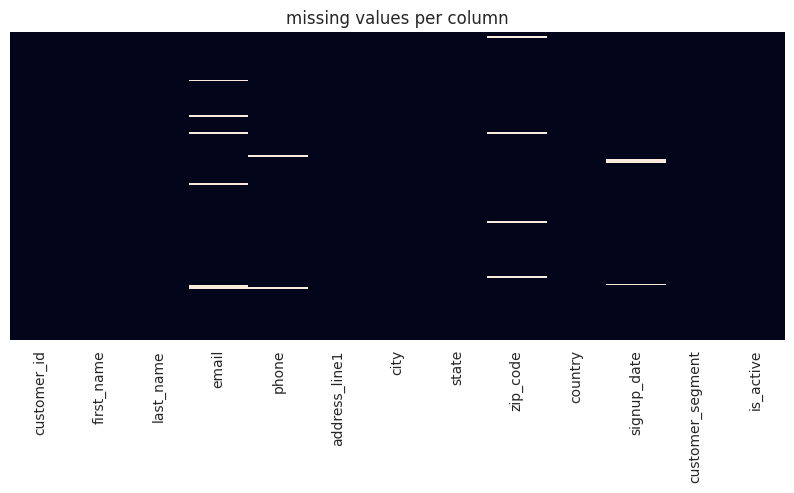

In [7]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('missing values per column')
plt.show()

In [8]:
for col in ['city', 'state', 'customer_segment', 'is_active']:
    print(df[col].value_counts())
    print()

city
Pune         21
Jaipur       18
Kolkata      17
Chennai      16
Hyderabad    16
Lucknow      14
Ahmedabad    12
mumbai        7
BANGALORE     6
bangalore     6
Bangalore     5
DELHI         5
Bengaluru     5
New Delhi     4
Delhi         4
Mumbai        3
MUMBAI        3
delhi         1
Name: count, dtype: int64

state
Maharashtra      34
Karnataka        22
Rajasthan        18
West Bengal      17
Tamil Nadu       16
Telangana        16
Uttar Pradesh    14
Delhi            14
Gujarat          12
Name: count, dtype: int64

customer_segment
Platinum    16
PLATINUM    16
Glod        15
SILVER      14
platinum    14
bronze      12
Bronze      11
Broze       11
silver      11
Silverr      9
GOLD         9
Gold         8
Silver       7
gold         7
BRONZE       3
Name: count, dtype: int64

is_active
Y        39
yes      35
true     33
1        26
True     25
N         2
False     1
0         1
no        1
Name: count, dtype: int64



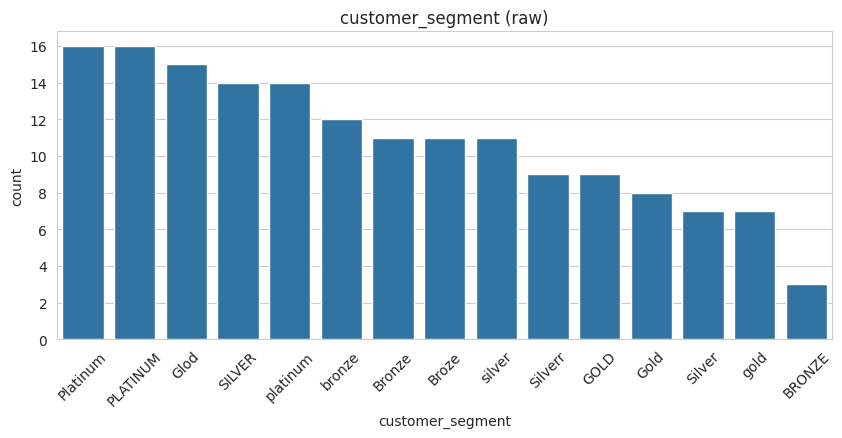

In [9]:
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='customer_segment', order=df['customer_segment'].value_counts().index)
plt.xticks(rotation=45)
plt.title('customer_segment (raw)')
plt.show()

In [10]:
df[['phone', 'signup_date', 'zip_code', 'email']].sample(12, random_state=3)

,phone,signup_date,zip_code,email
70,(965) 137-0985,01/16/2021,174612,gautam.rana37@example.com
150,01520643611,23-Jun-2021,371293,KEVIN.MITTAL98@EXAMPLE.COM
6,(685) 487-0998,24-Sep-2023,162299,aarna.nagarajan119@example.com
3,4057202590,2022-04-14,798515,krishna.baria140@example.com
47,3348434437,10-Jan-2022,758441,tripti.walia68@example.com
143,4278498084,10/18/2021,241182,tanay.toor11@gmail.com
76,0000000000,2021-10-18,847007,amol.ghosh40@example.com
133,01154479627,NaN,705964,fitan.samra57@example.com
102,(745) 458-9297,2023-07-20,001701,tara.parmar97@example.com
40,05182037788,2022-10-24,554665,raghavnagy49example.com


In [11]:
df[df['customer_id'].duplicated(keep=False)].sort_values('customer_id')

,customer_id,first_name,last_name,email,phone,address_line1,city,state,zip_code,country,signup_date,customer_segment,is_active
39,C0034,Yash,Wali,yash.wali34@example.com,(969) 379-2374,"59, Samra Road",Chennai,Tamil Nadu,407482,India,2022-03-27,Platinum,Y
74,C0034,Yash,Wali,YASH.WALI34@EXAMPLE.COM,(969) 379-2374,"59, Samra Road",Chennai,Tamil Nadu,407482,India,2022-03-27,Platinum,Y
99,C0045,Hemani,Sani,HEMANI.SANI45@EXAMPLE.COM,3690034324,"83, Pandya Circle",mumbai,Maharashtra,510762,India,05/02/2021,silver,1
126,C0045,Hemani,Sani,hemani.sani45@example.com,3690034324,"83, Pandya Circle",mumbai,Maharashtra,510762,India,05/02/2021,silver,1
111,C0098,Kevin,Mittal,kevin.mittal98@example.com,01520643611,"H.No. 051, Deo Marg",Chennai,Tamil Nadu,371293,India,23-Jun-2021,Bronze,true
150,C0098,Kevin,Mittal,KEVIN.MITTAL98@EXAMPLE.COM,01520643611,"H.No. 051, Deo Marg",Chennai,Tamil Nadu,371293,India,23-Jun-2021,Bronze,true
100,C0111,Ayushman,Mand,ayushman.mand111@example.com,03213348039,"05/99, Guha Street",DELHI,Delhi,NaN,India,03/06/2021,platinum,Y
129,C0111,Ayushman,Mand,AYUSHMAN.MAND111@EXAMPLE.COM,03213348039,"05/99, Guha Street",DELHI,Delhi,NaN,India,03/06/2021,platinum,Y
29,C0128,Yuvraj,Kara,yuvraj.kara128@example.com,+91-6894210447,"03, Deep Ganj",Jaipur,Rajasthan,625753,India,29/01/2023,Glod,Y
75,C0128,Yuvraj,Kara,YUVRAJ.KARA128@EXAMPLE.COM,+91-6894210447,"03, Deep Ganj",Jaipur,Rajasthan,625753,India,29/01/2023,Glod,Y


In [12]:
future_raw = df[df['signup_date'].str.contains('2027', na=False)]
future_raw[['customer_id', 'signup_date']]

,customer_id,signup_date
46,C0055,2027-01-15
113,C0078,2027-01-15


In [13]:
before = len(df)
before

163

In [14]:
def parse_date(x):
    if pd.isna(x):
        return pd.NaT
    x = str(x).strip()
    if x == '' or x.lower() == 'unknown':
        return pd.NaT
    if '/' in x:
        a, b, c = [int(i) for i in x.split('/')]
        if a > 12:
            return pd.Timestamp(year=c, month=b, day=a)
        if b > 12:
            return pd.Timestamp(year=c, month=a, day=b)
        return pd.Timestamp(year=c, month=b, day=a)
    if len(x) == 10 and x[4] == '-':
        return pd.to_datetime(x, format='%Y-%m-%d')
    return pd.to_datetime(x, format='%d-%b-%Y')


def is_ambiguous(x):
    if pd.isna(x) or '/' not in str(x):
        return False
    a, b, c = [int(i) for i in str(x).split('/')]
    return a <= 12 and b <= 12 and a != b

In [15]:
text_cols = df.select_dtypes(exclude='number').columns
for col in text_cols:
    df[col] = df[col].str.strip()
df = df.replace('', np.nan)
df.isnull().sum()

customer_id         0
first_name          0
last_name           0
email               6
phone               2
address_line1       0
city                0
state               0
zip_code            4
country             0
signup_date         3
customer_segment    0
is_active           0
dtype: int64

In [16]:
df['email'] = df['email'].str.lower()
df = df.drop_duplicates()
print(len(df))
print(df['customer_id'].duplicated().sum())

158
0


In [17]:
df['email'] = df['email'].str.replace(r'(?<!@)example\.com$', '@example.com', regex=True)
df['email'] = df['email'].str.replace(r'@example$', '@example.com', regex=True)
bad_email = df['email'].notna() & ~df['email'].str.contains(r'^[^@\s]+@[^@\s]+\.[a-z]+$', na=False)
print(bad_email.sum())
print(df['email'].isnull().sum())

0
6


In [18]:
df['name_key'] = (df['first_name'] + ' ' + df['last_name']).str.lower()
df['email_num'] = 'C' + df['email'].str.extract(r'(\d+)@')[0].str.zfill(4)
same_person = df[df.duplicated('name_key', keep=False)].sort_values(['name_key', 'customer_id'])
same_person[['customer_id', 'first_name', 'last_name', 'email', 'email_num', 'city', 'signup_date', 'customer_segment']]

,customer_id,first_name,last_name,email,email_num,city,signup_date,customer_segment
62,C0059,Adweta,Lad,adweta.lad59@example.com,C0059,Hyderabad,10/02/2023,Broze
56,C0171,Adweta,Lad,adweta.lad59@gmail.com,C0059,Hyderabad,10/02/2023,Broze
120,C0019,Anmol,Rai,anmol.rai19@example.com,C0019,Hyderabad,06/06/2022,SILVER
146,C0175,Anmol,Rai,anmol.rai19@example.com,C0019,Hyderabad,06/06/2022,SILVER
96,C0137,Ekanta,Thaman,ekanta.thaman137@example.com,C0137,bangalore,2023-08-23,silver
34,C0170,Ekanta,Thaman,ekanta.thaman137@gmail.com,C0137,bangalore,2023-08-23,silver
136,C0102,Farhan,Vaidya,farhan.vaidya102@example.com,C0102,Jaipur,05/10/2023,Platinum
73,C0176,Farhan,Vaidya,farhan.vaidya102@gmail.com,C0102,Jaipur,05/10/2023,Platinum
140,C0144,Raksha,Raj,raksha.raj144@example.com,C0144,Kolkata,03/09/2022,PLATINUM
105,C0173,Raksha,Raj,raksha.raj144@gmail.com,C0144,Kolkata,03/09/2022,PLATINUM


In [19]:
df = df.sort_values('customer_id')
master = df.drop_duplicates('name_key', keep='first')[['name_key', 'customer_id']]
master = master.rename(columns={'customer_id': 'master_id'})
df = df.merge(master, on='name_key', how='left')
id_map = df.loc[df['customer_id'] != df['master_id'], ['customer_id', 'master_id', 'email_num']]
print((id_map['email_num'] == id_map['master_id']).all())
id_map

True


,customer_id,master_id,email_num
150,C0170,C0137,C0137
151,C0171,C0059,C0059
152,C0172,C0129,C0129
153,C0173,C0144,C0144
154,C0174,C0091,C0091
155,C0175,C0019,C0019
156,C0176,C0102,C0102
157,C0177,C0011,C0011


In [20]:
id_map[['customer_id', 'master_id']].to_csv('customer_id_map.csv', index=False)
df = df[df['customer_id'] == df['master_id']]
df = df.drop(columns=['master_id', 'name_key', 'email_num']).reset_index(drop=True)
df.shape

(150, 13)

In [21]:
df['phone'] = df['phone'].str.replace(r'\D', '', regex=True)
df['phone'] = df['phone'].str.replace(r'^91(?=\d{10}$)', '', regex=True)
df['phone'] = df['phone'].str.replace(r'^0(?=\d{10}$)', '', regex=True)
print(df['phone'].str.len().value_counts())

phone
10.0    147
0.0       1
Name: count, dtype: int64


In [22]:
df.loc[df['phone'].str.len() != 10, 'phone'] = np.nan
df['phone'].isnull().sum()

np.int64(3)

In [23]:
df['city'] = df['city'].str.title()
df['city'] = df['city'].replace({'Bengaluru': 'Bangalore', 'New Delhi': 'Delhi'})
df['city'].value_counts()

city
Bangalore    21
Pune         21
Jaipur       16
Kolkata      16
Chennai      14
Hyderabad    14
Lucknow      12
Delhi        12
Mumbai       12
Ahmedabad    12
Name: count, dtype: int64

In [24]:
df.loc[~df['zip_code'].str.fullmatch(r'\d{6}', na=False), 'zip_code'] = np.nan
df['zip_code'].isnull().sum()

np.int64(6)

In [25]:
df['customer_segment'] = df['customer_segment'].str.lower()
df['customer_segment'] = df['customer_segment'].replace({'glod': 'gold', 'broze': 'bronze', 'silverr': 'silver'})
df['customer_segment'] = df['customer_segment'].str.title()
df['customer_segment'].value_counts()

customer_segment
Platinum    41
Gold        37
Silver      37
Bronze      35
Name: count, dtype: int64

In [26]:
bool_map = {'y': True, 'yes': True, 'true': True, '1': True,
            'n': False, 'no': False, 'false': False, '0': False}
df['is_active'] = df['is_active'].astype(str).str.lower().map(bool_map)
print(df['is_active'].isnull().sum())
df['is_active'].value_counts()

0


is_active
True     145
False      5
Name: count, dtype: int64

In [27]:
df['signup_ambiguous'] = df['signup_date'].apply(is_ambiguous)
df['signup_date'] = df['signup_date'].apply(parse_date)
print(df['signup_ambiguous'].sum())
df['signup_date'].describe()

23


count                           146
mean     2022-07-29 02:47:40.273972
min             2021-01-02 00:00:00
25%             2021-11-25 12:00:00
50%             2022-06-10 12:00:00
75%             2023-05-07 12:00:00
max             2027-01-15 00:00:00
Name: signup_date, dtype: object

In [28]:
df['signup_future'] = df['signup_date'] > pd.Timestamp.today()
print(df['signup_future'].sum())
df.loc[df['signup_future'], ['customer_id', 'signup_date']]

2


,customer_id,signup_date
54,C0055,2027-01-15
77,C0078,2027-01-15


In [29]:
df.loc[df['signup_future'], 'signup_date'] = pd.NaT
df['signup_date'].max()

Timestamp('2023-12-28 00:00:00')

In [30]:
print(before, '->', len(df))
df.info()

163 -> 150
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customer_id       150 non-null    str           
 1   first_name        150 non-null    str           
 2   last_name         150 non-null    str           
 3   email             144 non-null    str           
 4   phone             147 non-null    str           
 5   address_line1     150 non-null    str           
 6   city              150 non-null    str           
 7   state             150 non-null    str           
 8   zip_code          144 non-null    str           
 9   country           150 non-null    str           
 10  signup_date       144 non-null    datetime64[us]
 11  customer_segment  150 non-null    str           
 12  is_active         150 non-null    bool          
 13  signup_ambiguous  150 non-null    bool          
 14  signup_future     150 non-

In [31]:
df.isnull().sum()

customer_id         0
first_name          0
last_name           0
email               6
phone               3
address_line1       0
city                0
state               0
zip_code            6
country             0
signup_date         6
customer_segment    0
is_active           0
signup_ambiguous    0
signup_future       0
dtype: int64

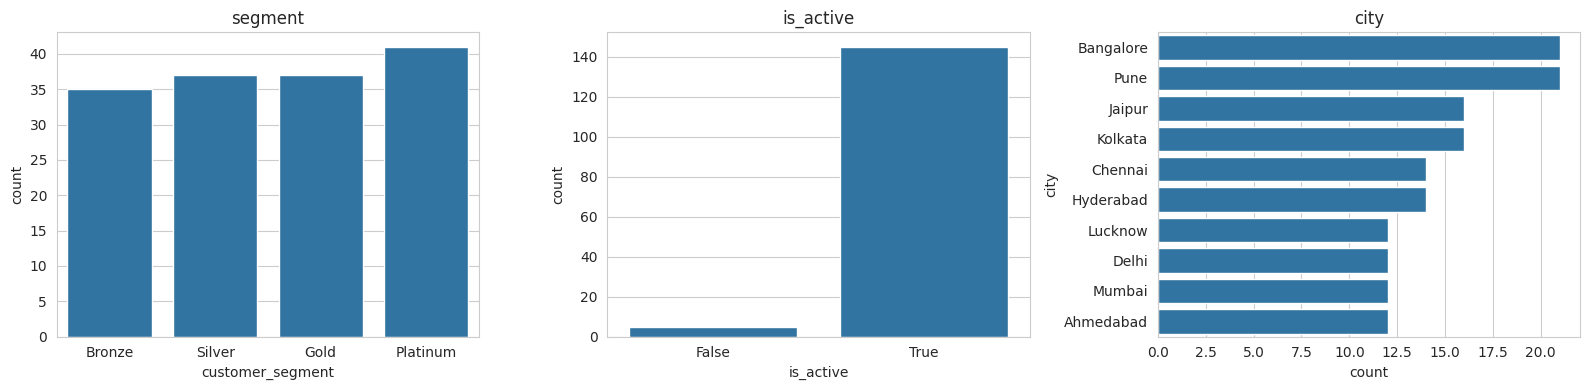

In [32]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x='customer_segment', order=['Bronze', 'Silver', 'Gold', 'Platinum'], ax=ax[0])
sns.countplot(data=df, x='is_active', ax=ax[1])
sns.countplot(data=df, y='city', order=df['city'].value_counts().index, ax=ax[2])
ax[0].set_title('segment')
ax[1].set_title('is_active')
ax[2].set_title('city')
plt.tight_layout()
plt.show()

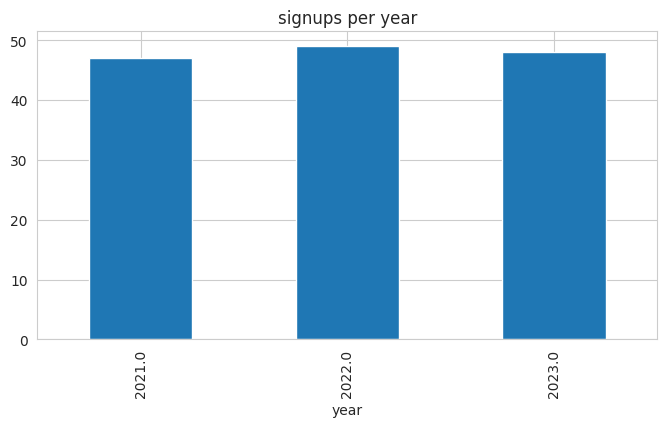

In [33]:
plt.figure(figsize=(8, 4))
df['signup_date'].dt.year.value_counts().sort_index().plot(kind='bar')
plt.title('signups per year')
plt.xlabel('year')
plt.show()

In [34]:
pd.crosstab(df['customer_segment'], df['is_active'])

is_active,False,True
customer_segment,,
Bronze,0,35
Gold,2,35
Platinum,1,40
Silver,2,35


In [35]:
df.to_csv('customers_clean.csv', index=False)
df.head()

,customer_id,first_name,last_name,email,phone,address_line1,city,state,zip_code,country,signup_date,customer_segment,is_active,signup_ambiguous,signup_future
0,C0001,Isaac,Bakshi,isaac.bakshi1@example.com,8196001338,"H.No. 265, Dugal Road",Bangalore,Karnataka,838637,India,2023-03-23,Bronze,True,False,False
1,C0002,Tanveer,Nayar,tanveer.nayar2@example.com,9407816184,"164, Patla Chowk",Lucknow,Uttar Pradesh,931034,India,2021-04-22,Gold,True,False,False
2,C0003,Nicholas,Prabhakar,nicholas.prabhakar3@example.com,8327648350,"767, Lanka Street",Jaipur,Rajasthan,056413,India,2022-01-24,Platinum,True,False,False
3,C0004,Liam,Koshy,liam.koshy4@example.com,6532871012,"48/01, Loke Circle",Kolkata,West Bengal,691669,India,2023-03-27,Bronze,True,False,False
4,C0005,Harini,Choudhury,harini.choudhury5@example.com,8281489325,"H.No. 543, Khosla Nagar",Bangalore,Karnataka,880957,India,2021-11-18,Gold,True,False,False
